Loading DataFrame:
  data_for_variance_50_2_mask/TNG50-2_z3_637Halos_DLAMode_Stratified_run0_seed42.pkl
Loaded 231,231 rows.
Columns: ['halo_id', 'halo_mass', 'halo_r200_mpc', 'redshift', 'skewer_id', 'axis', 'r_multiplier', 'impact_kpc', 'total_col_den', 'log_n_hi', 'eq_width', 'std_dev', 'skewness', 'kurtosis', 'mean_wave', 'mean_vel', 'vel_coherent', 'vel_peak_shift', 'wave', 'flux', 'vel_axis', 'vel_aligned', 'chi_axis', 'n_hi_col']

Valid skewers (with spectra): 231,231
Impact parameters (29): [0.000e+00 1.000e-02 2.000e-02 3.000e-02 4.000e-02 6.000e-02 8.000e-02
 1.000e-01 1.400e-01 1.900e-01 2.500e-01 3.400e-01 4.600e-01 6.100e-01
 8.200e-01 1.100e+00 1.470e+00 1.980e+00 2.650e+00 3.560e+00 4.770e+00
 6.400e+00 8.580e+00 1.151e+01 1.544e+01 2.072e+01 2.779e+01 3.728e+01
 5.000e+01]


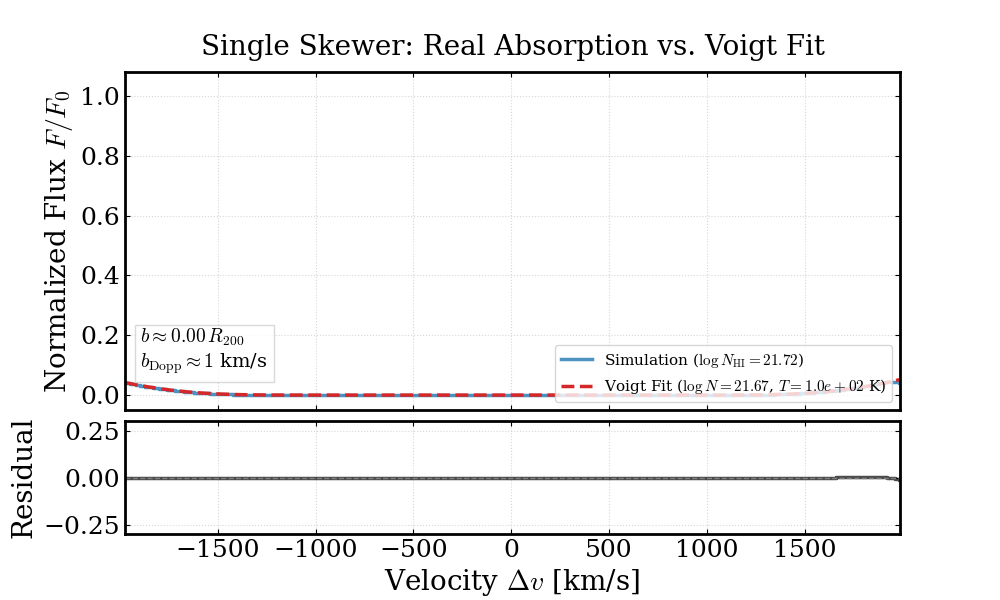

Starting parallel batch fitting...
Skewers to fit (log_n_hi > 1.0): 114,350


Fitting:   0%|          | 0/114350 [00:00<?, ?it/s]


Fitting complete in 0.9 min.
Successful fits: 114,350 / 114,350
Impact parameters for ridgeline (18):
  [0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1, 0.14, 0.19, 0.25, 0.34, 0.46, 0.61, 0.82, 1.1, 1.47, 1.98]


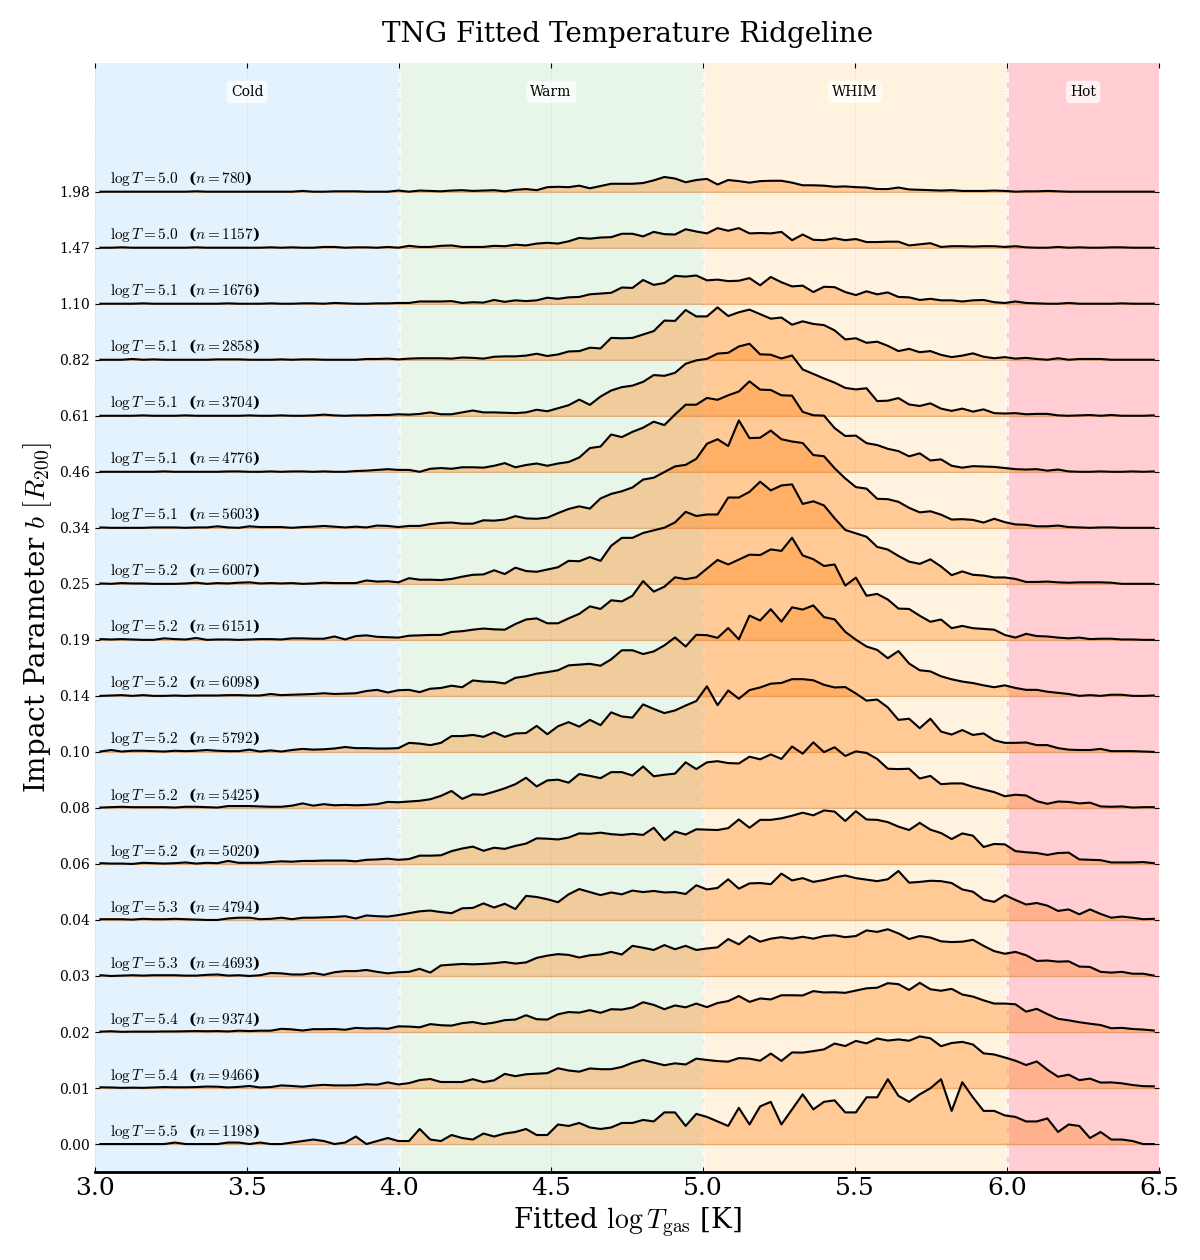

Plotting 86,936 fitted absorbers.


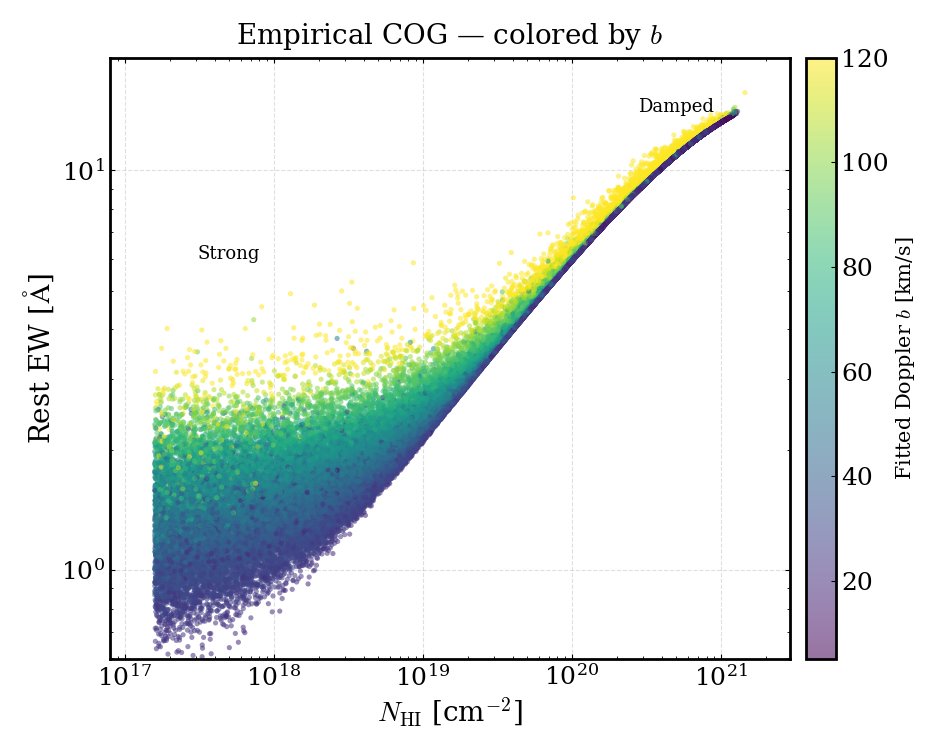

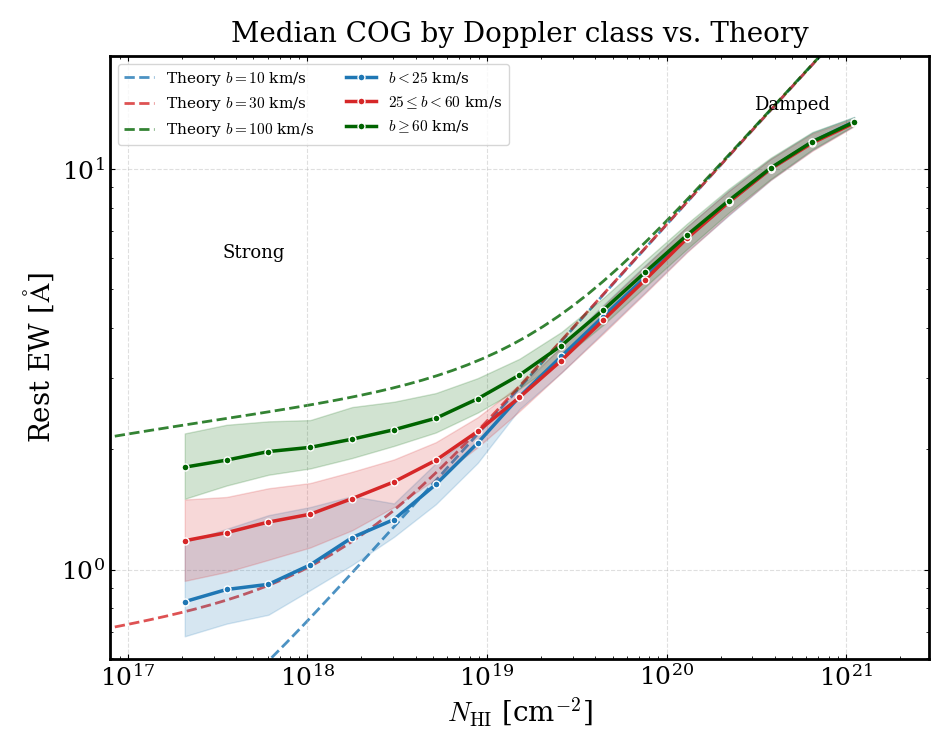

Recomputing EW (A) from saved spectra...
Recomputing EW (B) synthetic single-Voigt from fitted (N_HI, b)...

Sanity check  ew_data_integ / eq_width :
   median = 1.0000   16-84% = [1.0000, 1.0000]
   (should be ~1.0 -> confirms same integrand/units as pipeline)

Real/Voigt  ew_data_integ / ew_voigt_synth :
   median = 0.7539   16-84% = [0.6332, 0.9774]
   (>1 -> real profile is broader than a single Voigt; THIS is the
    physical reason the empirical points sit above the theory curves)


In [1]:
# ==============================================================================
# CELL 0: IMPORTS & CONFIGURATION
# ==============================================================================
import os
import glob
import time
import concurrent.futures
import numpy as np
import pandas as pd
import scipy.constants as const
from scipy.special import wofz
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from tqdm.auto import tqdm


def matplotlib_default_config():
    """Default dictionary configurations for publication-ready plots."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm",
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "legend.fontsize": 12,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.labelsize': 18,
        'ytick.labelsize': 18,
    }
    return font, rcnew


%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

HUBBLE_H = 0.6774
MASS_CONVERSION_FACTOR = 1e10 / HUBBLE_H
# ==============================================================================
# CELL 1: DATA LOADING & PRE-PROCESSING
#   Choose ONE TNG run file here.
# ==============================================================================

# ----------------------------------------------------------------------------
# >>> CHOOSE YOUR FILE <<<
#   This is intentionally left open. Point it to any single run .pkl you have.
#   Examples:
#     'data_for_variance_50_2_mask/TNG50-2_z3_..._DLAMode_Stratified_run0.pkl'
#     'data_grid/TNG50-2_z3_Grid_500x500_DLAMode.pkl'
# ----------------------------------------------------------------------------
FILE_PATH = 'data_for_variance_50_2_mask/TNG50-2_z3_637Halos_DLAMode_Stratified_run0_seed42.pkl'

print(f"Loading DataFrame:\n  {FILE_PATH}")
df_raw = pd.read_pickle(FILE_PATH)
print(f"Loaded {len(df_raw):,} rows.")
print(f"Columns: {list(df_raw.columns)}")

# --- Physical halo mass ---
if 'halo_mass_msun' not in df_raw.columns:
    df_raw['halo_mass_msun'] = df_raw['halo_mass'] * MASS_CONVERSION_FACTOR

# --- Group impact parameters ---
df_raw['r_mult_round'] = df_raw['r_multiplier'].round(2)

# We need the spectra to fit. Drop rows missing wave/flux.
df_clean = df_raw.dropna(subset=['wave', 'flux', 'log_n_hi']).copy()

unique_radii = np.sort(df_clean['r_mult_round'].unique())
n_panels = len(unique_radii)

print(f"\nValid skewers (with spectra): {len(df_clean):,}")
print(f"Impact parameters ({n_panels}): {unique_radii}")
# ==============================================================================
# CELL 2: PHYSICS CONSTANTS & VOIGT PROFILE
# ==============================================================================
LAMBDA_REST_A = 1215.670100   # Lya rest wavelength [Angstrom]
F_OSC         = 0.416400      # oscillator strength
A21_HZ        = 6.265e8       # Einstein A coefficient [1/s]
C_KM_S        = const.c / 1000.0


def full_voigt_approximation(wave_A, log_N_HI, v_shift_kms, T_gas_K):
    """
    Computes the normalized transmitted flux F/F0 for a single HI Lya line
    using the full Voigt profile via the Faddeeva function (wofz).

    Parameters
    ----------
    wave_A      : observed/rest wavelength array [Angstrom]
    log_N_HI    : log10 column density [cm^-2]
    v_shift_kms : line-of-sight velocity shift [km/s]
    T_gas_K     : gas temperature [K]  -> sets the Doppler parameter b
    """
    lambda0 = LAMBDA_REST_A * 1e-10           # m
    N = (10**log_N_HI) * 1e4                   # convert cm^-2 -> m^-2
    T_gas_K = max(T_gas_K, 1.0)

    # Doppler parameter (thermal): b = sqrt(2 k T / m_p)
    b_doppler = np.sqrt(2 * const.k * T_gas_K / const.m_p)

    v_shifted = (const.c * (wave_A * 1e-10 - lambda0) / lambda0) - (v_shift_kms * 1000.0)

    u = v_shifted / b_doppler
    a = (A21_HZ * lambda0) / (4 * np.pi * b_doppler)

    phi_v   = np.real(wofz(u + 1j * a)) / (np.sqrt(np.pi) * b_doppler)
    sigma_v = ((const.e**2 * F_OSC) / (4 * const.epsilon_0 * const.m_e * const.c)) * lambda0 * phi_v

    return np.exp(-N * sigma_v)
# ==============================================================================
# CELL 3: SINGLE SKEWER VOIGT FIT INSPECTION (real absorption vs. fit)
#   Picks a skewer that actually has a strong absorber, for a nice example.
# ==============================================================================

# Pick an example: strongest absorber available (or change indices manually).
df_strong = df_clean[df_clean['log_n_hi'] > 19.0]
if len(df_strong) == 0:
    df_strong = df_clean[df_clean['log_n_hi'] > 15.0]

example_row = df_strong.sort_values('log_n_hi', ascending=False).iloc[0]

w_data   = np.asarray(example_row['wave'], dtype=float)
f_data   = np.asarray(example_row['flux'], dtype=float)
sim_nhi  = example_row['log_n_hi']
b_example = example_row['r_mult_round']

v_axis = C_KM_S * (w_data - LAMBDA_REST_A) / LAMBDA_REST_A

# Fit this single spectrum
bounds = ([11.0, -1000.0, 1e2], [27.0, 1000.0, 1e12])
guess  = 20.0 if np.min(f_data) < 0.05 else 14.0
try:
    popt, _ = curve_fit(full_voigt_approximation, w_data, f_data,
                        p0=[guess, 0.0, 2e4], bounds=bounds, maxfev=5000)
    f_fit, fit_nhi, fit_v, fit_T = full_voigt_approximation(w_data, *popt), popt[0], popt[1], popt[2]
except RuntimeError:
    f_fit, fit_nhi, fit_v, fit_T = np.ones_like(f_data), np.nan, np.nan, np.nan

# --- Plot: spectrum + residuals ---
fig_insp, (ax_main, ax_res) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True,
    gridspec_kw={'height_ratios': [3, 1], 'hspace': 0.05},
)

ax_main.step(v_axis, f_data, where='mid', color='tab:blue', alpha=0.8,
             label=rf'Simulation ($\log N_{{\rm HI}}={sim_nhi:.2f}$)')
ax_main.plot(v_axis, f_fit, color='tab:red', ls='--', lw=2.5,
             label=rf'Voigt Fit ($\log N={fit_nhi:.2f}$, $T={fit_T:.1e}$ K)')

b_kms = np.sqrt(2 * const.k * fit_T / const.m_p) / 1000.0 if np.isfinite(fit_T) else np.nan
ax_main.text(0.02, 0.10,
             rf"$b \approx {b_example:.2f}\,R_{{200}}$" + "\n" +
             rf"$b_{{\rm Dopp}} \approx {b_kms:.0f}$ km/s",
             transform=ax_main.transAxes,
             bbox=dict(facecolor='white', alpha=0.85, edgecolor='lightgray'),
             va='bottom')

ax_main.set_ylim(-0.05, 1.08)
ax_main.set_ylabel(r"Normalized Flux $F/F_0$")
ax_main.grid(True, ls=':', alpha=0.5)
ax_main.legend(loc='lower right', frameon=True, fontsize=11)
ax_main.set_title("Single Skewer: Real Absorption vs. Voigt Fit", pad=12)

ax_res.step(v_axis, f_data - f_fit, where='mid', color='black', alpha=0.7)
ax_res.axhline(0.0, color='gray', ls='--', lw=1.0)
ax_res.set_ylim(-0.3, 0.3)
ax_res.set_ylabel("Residual")
ax_res.set_xlabel(r"Velocity $\Delta v$ [km/s]")
ax_res.grid(True, ls=':', alpha=0.5)

ax_res.set_xlim(v_axis.min(), v_axis.max())
plt.show()
# ==============================================================================
# CELL 4: PARALLEL BATCH FITTING  (extract temperatures)
#   Only fits skewers that actually contain absorption.
# ==============================================================================
print(f"Starting parallel batch fitting...")
t0 = time.time()

FIT_BOUNDS = ([11.0, -1000.0, 1e2], [27.0, 1000.0, 1e12])

# Only fit skewers with a real absorber (saves enormous time on empty/forest).
# The pipeline forces sub-threshold skewers to log_n_hi = 0.0 in DLA mode,
# so requiring log_n_hi > 1.0 keeps only the HCD population.
df_to_fit = df_clean[df_clean['log_n_hi'] > 1.0].copy()
print(f"Skewers to fit (log_n_hi > 1.0): {len(df_to_fit):,}")


def fit_spectrum(payload):
    """payload = (idx, wave, flux, log_n_hi). Returns dict of fit results."""
    idx, w_data, f_data, sim_nhi = payload
    w_data = np.asarray(w_data, dtype=float)
    f_data = np.asarray(f_data, dtype=float)

    # Reject flat / noiseless spectra (no absorption to constrain T)
    if np.min(f_data) > 0.99:
        return {'index': idx, 'fit_log_nhi': np.nan,
                'fit_v_shift': np.nan, 'fit_T_gas': np.nan}

    guess = 20.0 if np.min(f_data) < 0.05 else 14.0
    try:
        popt, _ = curve_fit(full_voigt_approximation, w_data, f_data,
                            p0=[guess, 0.0, 2e4], bounds=FIT_BOUNDS, maxfev=2000)
        return {'index': idx, 'fit_log_nhi': popt[0],
                'fit_v_shift': popt[1], 'fit_T_gas': popt[2]}
    except RuntimeError:
        return {'index': idx, 'fit_log_nhi': np.nan,
                'fit_v_shift': np.nan, 'fit_T_gas': np.nan}


payloads = [(idx, row['wave'], row['flux'], row['log_n_hi'])
            for idx, row in df_to_fit.iterrows()]

with concurrent.futures.ProcessPoolExecutor(max_workers=20) as executor:
    results = list(tqdm(executor.map(fit_spectrum, payloads),
                        total=len(payloads), desc="Fitting"))

df_results = pd.DataFrame(results).set_index('index')

# Merge fit results back into the main dataframe
df_clean = df_clean.join(df_results)

# Derived: Doppler b [km/s] from fitted temperature
df_clean['fit_b_kms'] = np.sqrt(
    2 * const.k * df_clean['fit_T_gas'].clip(lower=1.0) / const.m_p
) / 1000.0

n_ok = df_clean['fit_T_gas'].notna().sum()
print(f"\nFitting complete in {(time.time()-t0)/60:.1f} min.")
print(f"Successful fits: {n_ok:,} / {len(df_to_fit):,}")
# ==============================================================================
# CELL 5: RIDGELINE — IMPACT PARAMETER vs. FITTED TEMPERATURE
# ==============================================================================

# --- Configuration ---
SELECTED_B = [b for b in unique_radii if (b >= 0.0 and b <= 2.0)]
print(f"Impact parameters for ridgeline ({len(SELECTED_B)}):\n  {SELECTED_B}")

# Temperature axis (log10 T)
T_LOG_MIN, T_LOG_MAX = 3.0, 6.5
num_bins  = 100
hist_bins = np.linspace(T_LOG_MIN, T_LOG_MAX, num_bins + 1)
x_hist    = (hist_bins[:-1] + hist_bins[1:]) / 2

overlap_factor = 1.8   # cosmetic vertical scaling of curves


def density_hist(values, bins, tot):
    """Probability density per dex, normalized by total skewers in the row."""
    if len(values) < 2 or tot == 0:
        return np.zeros(len(bins) - 1)
    counts, _ = np.histogram(values, bins=bins)
    bw = bins[1] - bins[0]
    return counts / (tot * bw)


fig_h = max(8, 0.7 * len(SELECTED_B))
fig_ridge, ax = plt.subplots(figsize=(12, fig_h))

# Background regions: WHIM / warm / hot phases (illustrative)
c_cold = '#E3F2FD'   # T < 1e4 (cold neutral)
c_warm = '#E8F5E9'   # 1e4 - 1e5 (warm photoionized / typical Lya)
c_whim = '#FFF3E0'   # 1e5 - 1e6 (WHIM)
c_hot  = '#FFCDD2'   # > 1e6 (hot)

ax.axvspan(T_LOG_MIN, 4.0, color=c_cold, zorder=0)
ax.axvspan(4.0, 5.0, color=c_warm, zorder=0)
ax.axvspan(5.0, 6.0, color=c_whim, zorder=0)
ax.axvspan(6.0, T_LOG_MAX, color=c_hot, zorder=0)
for xv in [4.0, 5.0, 6.0]:
    ax.axvline(xv, color='white', ls='--', lw=2.0, zorder=0)

bbox_props = dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7, edgecolor="none")
ax.text(3.5, 0.98, 'Cold',  transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
ax.text(4.5, 0.98, 'Warm',  transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
ax.text(5.5, 0.98, 'WHIM',  transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)
ax.text(6.25, 0.98, 'Hot',  transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=10, bbox=bbox_props, zorder=10)

ax.grid(axis='x', ls=':', alpha=0.4)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

y_ticks, y_labels = [], []

for i_b, b_val in enumerate(SELECTED_B):
    b_round = np.round(b_val, 2)
    y_base = i_b
    y_ticks.append(y_base)
    y_labels.append(f"{b_val:.2f}")
    ax.axhline(y_base, color='gray', lw=0.8, alpha=0.3, zorder=1)

    df_b = df_clean[(df_clean['r_mult_round'] == b_round)]
    tot  = len(df_b)   # total skewers at this b (incl. forest/non-fitted)

    # Valid fitted temperatures (above 150 K artifact floor)
    temps = df_b['fit_T_gas'].dropna().values
    temps = temps[temps > 150.0]
    log_t = np.log10(temps)
    log_t = log_t[(log_t >= T_LOG_MIN) & (log_t <= T_LOG_MAX)]

    dens = density_hist(log_t, hist_bins, tot) * overlap_factor

    ax.fill_between(x_hist, y_base, y_base + dens,
                    color='tab:orange', alpha=0.35, zorder=i_b + 3)
    ax.plot(x_hist, y_base + dens, color='black', lw=1.5, zorder=i_b + 5)

    # Median T annotation
    if len(temps) > 0:
        med = np.median(np.log10(temps))
        ax.text(T_LOG_MIN + 0.05, y_base + 0.15,
                rf"$\log T={med:.1f}$  ($n={len(temps)}$)",
                fontsize=11, fontweight='bold', zorder=20)

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels, fontsize=10)
ax.set_xlim(T_LOG_MIN, T_LOG_MAX)
ax.set_ylim(-0.5, len(SELECTED_B) - 1 + overlap_factor + 0.5)
ax.set_xlabel(r"Fitted $\log T_{\rm gas}$ [K]")
ax.set_ylabel(r"Impact Parameter $b \ [R_{200}]$")
ax.set_title(rf"TNG Fitted Temperature Ridgeline", pad=15)

plt.tight_layout()
plt.show()
# ==============================================================================
# CELL 6a (FINAL): EMPIRICAL COG SCATTER — colored by Doppler b
#   eq_width confirmed to be REST-FRAME ANGSTROM (np.trapz over wave).
# ==============================================================================

# --- eq_width is already rest-frame Angstrom (verified from radii_skewers.py) ---
df_clean['ew_rest_A'] = df_clean['eq_width'].astype(float)

# --- Sample selection ---
mask = (
    df_clean['log_n_hi'].between(11.5, 22.5) &
    (df_clean['ew_rest_A'] > 0) &
    df_clean['fit_T_gas'].notna() &
    (df_clean['fit_T_gas'] > 150.0)
)
df_plot = df_clean[mask].copy()

x_log  = df_plot['log_n_hi'].values
x_vals = 10**x_log
y_vals = df_plot['ew_rest_A'].values
b_vals = df_plot['fit_b_kms'].values

print(f"Plotting {len(df_plot):,} fitted absorbers.")

fig, axL = plt.subplots(figsize=(9.5, 7.5))

scL = axL.scatter(x_vals, y_vals, c=b_vals, cmap='viridis',
                  vmin=5.0, vmax=120.0, s=14, alpha=0.55,
                  edgecolor='none', zorder=2)

cbar = fig.colorbar(scL, ax=axL, pad=0.02)
cbar.set_label(r'Fitted Doppler $b$ [km/s]', fontsize=15)

axL.set_xscale('log')
axL.set_yscale('log')
axL.set_xlabel(r'$N_{\rm HI}$ [cm$^{-2}$]')
axL.set_ylabel(r'Rest EW [$\mathrm{\AA}$]')
axL.set_title(r'Empirical COG — colored by $b$', pad=10)
axL.grid(True, ls='--', alpha=0.4)

axL.text(5e17, 6.0,  'Strong', fontsize=13, ha='center')
axL.text(5e20, 14.0, 'Damped', fontsize=13, ha='center')

axL.set_xlim(10**(x_log.min() - 0.3), 10**(x_log.max() + 0.3))
axL.set_ylim(np.nanpercentile(y_vals, 0.5) * 0.7,
             np.nanpercentile(y_vals, 99.9) * 1.4)

plt.tight_layout()
plt.show()
# ==============================================================================
# CELL 6b (FINAL): MEDIAN COG BY DOPPLER CLASS + THEORETICAL OVERLAY
#   Empirical medians (16-84%) compared against the theoretical COG curves
#   computed earlier (b = 10, 30, 100 km/s).
# ==============================================================================

# --- Ensure theoretical COG curves exist (recompute if needed) ---
try:
    cog_theory  # noqa
    logN_grid   # noqa
except NameError:
    def voigt_optical_depth(wave_A, log_N_HI, b_kms):
        lambda0 = LAMBDA_REST_A * 1e-10
        N = (10**log_N_HI) * 1e4
        b_doppler = b_kms * 1000.0
        v = (const.c * (wave_A * 1e-10 - lambda0) / lambda0)
        u = v / b_doppler
        a = (A21_HZ * lambda0) / (4 * np.pi * b_doppler)
        phi_v = np.real(wofz(u + 1j * a)) / (np.sqrt(np.pi) * b_doppler)
        sigma_v = ((const.e**2 * F_OSC) / (4 * const.epsilon_0 * const.m_e * const.c)) * lambda0 * phi_v
        return N * sigma_v

    def rest_equivalent_width(log_N_HI, b_kms, half_window_A=120.0, n_pts=200001):
        wave = np.linspace(LAMBDA_REST_A - half_window_A, LAMBDA_REST_A + half_window_A, n_pts)
        tau = voigt_optical_depth(wave, log_N_HI, b_kms)
        return np.trapz(1.0 - np.exp(-tau), wave)

    logN_grid = np.linspace(12.0, 22.0, 120)
    cog_theory = {b: np.array([rest_equivalent_width(lN, b) for lN in logN_grid])
                  for b in [10.0, 30.0, 100.0]}

# --- Empirical binned medians, split by Doppler class ---
b_classes = [
    (0.0,    25.0,   'tab:blue',  r'$b < 25$ km/s'),
    (25.0,   60.0,   'tab:red',   r'$25 \leq b < 60$ km/s'),
    (60.0,   np.inf, 'darkgreen', r'$b \geq 60$ km/s'),
]

# Theoretical reference curves (dashed, matched roughly to each class)
theory_for_class = {'tab:blue': 10.0, 'tab:red': 30.0, 'darkgreen': 100.0}

nhi_bins = np.linspace(x_log.min(), x_log.max(), 18)
nhi_cent = 0.5 * (nhi_bins[:-1] + nhi_bins[1:])

fig, axR = plt.subplots(figsize=(9.5, 7.5))

# --- Theoretical curves (background, dashed) ---
for b_val, color in zip([10.0, 30.0, 100.0], ['tab:blue', 'tab:red', 'darkgreen']):
    axR.plot(10**logN_grid, cog_theory[b_val], color=color, lw=2.0, ls='--',
             alpha=0.8, zorder=1,
             label=rf'Theory $b={b_val:.0f}$ km/s')

# --- Empirical medians + bands ---
for b_lo, b_hi, color, label in b_classes:
    sel = (b_vals >= b_lo) & (b_vals < b_hi)
    if sel.sum() < 10:
        continue

    xb, yb = x_log[sel], y_vals[sel]
    med = np.full(len(nhi_cent), np.nan)
    p16 = np.full(len(nhi_cent), np.nan)
    p84 = np.full(len(nhi_cent), np.nan)

    for i in range(len(nhi_cent)):
        in_bin = (xb >= nhi_bins[i]) & (xb < nhi_bins[i + 1])
        if in_bin.sum() >= 5:
            vals = yb[in_bin]
            med[i] = np.median(vals)
            p16[i] = np.percentile(vals, 16)
            p84[i] = np.percentile(vals, 84)

    good = np.isfinite(med)
    axR.fill_between(10**nhi_cent[good], p16[good], p84[good],
                     color=color, alpha=0.18, zorder=2)
    axR.plot(10**nhi_cent[good], med[good], color=color, lw=2.5,
             marker='o', ms=5, mec='white', zorder=4, label=label)

axR.set_xscale('log')
axR.set_yscale('log')
axR.set_xlabel(r'$N_{\rm HI}$ [cm$^{-2}$]')
axR.set_ylabel(r'Rest EW [$\mathrm{\AA}$]')
axR.set_title('Median COG by Doppler class vs. Theory', pad=10)
axR.grid(True, ls='--', alpha=0.4)

axR.text(5e17, 6.0,  'Strong', fontsize=13, ha='center')
axR.text(5e20, 14.0, 'Damped', fontsize=13, ha='center')

axR.set_xlim(10**(x_log.min() - 0.3), 10**(x_log.max() + 0.3))
axR.set_ylim(np.nanpercentile(y_vals, 0.5) * 0.7,
             np.nanpercentile(y_vals, 99.9) * 1.4)

axR.legend(loc='upper left', frameon=True, fontsize=11, ncol=2)

plt.tight_layout()
plt.show()
# ==============================================================================
# CELL 6-RECOMPUTE: EW computed identically to the theoretical model
#   Two recomputations from data already in memory:
#     (A) ew_data_integ : integrate (1 - flux) over the SAVED TNG spectrum,
#                         using the SAME integrand as theory. This reproduces
#                         the real multi-component profile (~ eq_width).
#     (B) ew_voigt_synth: rebuild a SINGLE Voigt from the fitted (N_HI, b) and
#                         integrate it with rest_equivalent_width(). This is
#                         the true apples-to-apples comparison with theory.
# ==============================================================================

import numpy as np

# --- (A) Recompute from the saved TNG flux (same integrand as theory) --------
def ew_from_saved_spectrum(row):
    wave = np.asarray(row['wave'], dtype=float)   # Angstrom (rest)
    flux = np.asarray(row['flux'], dtype=float)
    if wave.size < 2:
        return np.nan
    order = np.argsort(wave)                       # ensure monotonic in lambda
    wave, flux = wave[order], flux[order]
    return np.trapz(1.0 - flux, x=wave)

# --- (B) Synthetic single-Voigt EW from the FITTED (N_HI, b) ------------------
#     Uses the exact same machinery as the theoretical COG.
def ew_synthetic_voigt(log_N_HI, b_kms):
    if not np.isfinite(log_N_HI) or not np.isfinite(b_kms) or b_kms <= 0:
        return np.nan
    return rest_equivalent_width(float(log_N_HI), float(b_kms))

# ----------------------------------------------------------------------------
# Apply to the cleaned sample (df_clean already filtered upstream)
# ----------------------------------------------------------------------------
print("Recomputing EW (A) from saved spectra...")
df_clean['ew_data_integ'] = df_clean.apply(ew_from_saved_spectrum, axis=1)

print("Recomputing EW (B) synthetic single-Voigt from fitted (N_HI, b)...")
df_clean['ew_voigt_synth'] = df_clean.apply(
    lambda r: ew_synthetic_voigt(r['log_n_hi'], r['fit_b_kms']), axis=1
)

# Sanity check: how close is the re-integration (A) to the pipeline eq_width?
ok = (df_clean['eq_width'] > 0) & df_clean['ew_data_integ'].notna()
ratio = (df_clean.loc[ok, 'ew_data_integ'] / df_clean.loc[ok, 'eq_width'])
print(f"\nSanity check  ew_data_integ / eq_width :")
print(f"   median = {ratio.median():.4f}   "
      f"16-84% = [{ratio.quantile(0.16):.4f}, {ratio.quantile(0.84):.4f}]")
print("   (should be ~1.0 -> confirms same integrand/units as pipeline)")

# Sanity check: synthetic-Voigt vs real-spectrum EW (this IS the difference
# between 'single Voigt' and 'real multi-component' profile)
ok2 = (df_clean['ew_data_integ'] > 0) & (df_clean['ew_voigt_synth'] > 0)
ratio2 = (df_clean.loc[ok2, 'ew_data_integ'] / df_clean.loc[ok2, 'ew_voigt_synth'])
print(f"\nReal/Voigt  ew_data_integ / ew_voigt_synth :")
print(f"   median = {ratio2.median():.4f}   "
      f"16-84% = [{ratio2.quantile(0.16):.4f}, {ratio2.quantile(0.84):.4f}]")
print("   (>1 -> real profile is broader than a single Voigt; THIS is the")
print("    physical reason the empirical points sit above the theory curves)")